# PGD transferability vs. layers fine-tuned (eps = 5/255)

The surrogates of the labeled-images figure -- for each depth, the model fine-tuned on the
smallest labeled set that reaches victim - 1, saved at the first epoch that does (VGG-11 at
8 layers never does: its highest-accuracy epoch) -- are used as PGD sources against their
victim: L-inf eps = 5/255, alpha = 2/255, 75 steps, random start, CIFAR-10 test set,
fp32 models + fp64 cross-entropy. ASR = victim error on the adversarial examples.
Each point is the **median over three training seeds** (8, 9, 10: each re-draws the
labeled subset and the initialization). The dashed line is the white-box attack on the
victim (the highest of the three victims). The star is the from-scratch surrogate.

Data: `data/fig_transfer_vs_layers_archs_eps5255.csv` (from `postprocess.py`; raw results from
`../run_sources.sbatch` + `../run_pgd.sbatch`).

In [1]:
import os
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, MultipleLocator, NullFormatter, NullLocator

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
# Shared style of the two fine-tuning figures.
SURFACE = '#fcfcfb'                    # figure / axes background
INK_2 = '#52514e'                      # legend text, white-box line
GRID = '#e1e0d9'
ARCH_ORDER = ['ResNet-18', 'VGG-11', 'CNN']
ARCH_COLORS = {'ResNet-18': '#2a78d6', 'VGG-11': '#eb6834', 'CNN': '#009e73'}
ARCH_MARKERS = {'ResNet-18': 'o', 'VGG-11': '^', 'CNN': 's'}
SHORT = {'ResNet-18': 'ResNet', 'VGG-11': 'VGG', 'CNN': 'CNN'}
LEGEND_ORDER = ('CNN', 'VGG-11', 'ResNet-18')
SCRATCH_MARKER = '*'                   # the from-scratch surrogate, at x = n_layers
MAX_LAYERS = 21                        # x axis 1..21 (ResNet-18 depth)


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.set_axisbelow(True)
    ax.grid(True, color=GRID, linewidth=0.8)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('black')
    ax.tick_params(colors='black', labelsize=11.5, length=0)


def layers_axis(ax):
    """x = layers fine-tuned, 1..21; every layer ticked, odd ones labelled."""
    ticks = list(range(1, MAX_LAYERS + 1))
    ax.set_xlim(0, MAX_LAYERS + 1)
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.set_xticklabels([str(t) if t % 2 else '' for t in ticks])
    ax.tick_params(axis='x', labelsize=13)
    ax.set_xlabel('Layers fine-tuned', color='black', fontsize=15)


def save(fig, path):
    fig.tight_layout()
    fig.savefig(path, format='pdf', bbox_inches='tight', facecolor=SURFACE)
    print(f"-> {path}")

In [3]:
df = pd.read_csv('data/fig_transfer_vs_layers_archs_eps5255.csv')
df

,arch,label,n_layers,num_recovered,layers_finetuned,is_surrogate,labeled_images,asr_seed8,asr_seed9,asr_seed10,clean_acc_seed8,clean_acc_seed9,clean_acc_seed10,n_seeds,asr_median,white_box_asr
0,resnet18,ResNet-18,21,20,1,False,10,0.9860,0.9860,0.9855,91.87,92.35,92.01,3,0.9860,0.9864
1,resnet18,ResNet-18,21,19,2,False,10,0.9697,0.9741,0.9677,91.69,91.83,92.00,3,0.9697,0.9864
2,resnet18,ResNet-18,21,18,3,False,10,0.9905,0.9896,0.9895,92.18,92.11,91.84,3,0.9896,0.9864
3,resnet18,ResNet-18,21,17,4,False,20,0.9942,0.9954,0.9946,91.62,91.59,91.65,3,0.9946,0.9864
4,resnet18,ResNet-18,21,16,5,False,10,0.9870,0.9878,0.9883,91.34,91.50,91.52,3,0.9878,0.9864
5,resnet18,ResNet-18,21,15,6,False,20,0.9944,0.9931,0.9947,91.62,91.59,91.67,3,0.9944,0.9864
6,resnet18,ResNet-18,21,14,7,False,50,0.9943,0.9959,0.9948,91.71,91.61,91.69,3,0.9948,0.9864
7,resnet18,ResNet-18,21,13,8,False,500,0.9961,0.9950,0.9942,91.67,91.68,91.76,3,0.9950,0.9864
8,resnet18,ResNet-18,21,12,9,False,10000,0.9898,0.9887,0.9898,91.65,91.64,91.59,3,0.9898,0.9864
9,resnet18,ResNet-18,21,11,10,False,10000,0.9925,0.9909,0.9907,91.60,91.60,91.62,3,0.9909,0.9864


-> ../plots/fig_transfer_vs_layers_archs_eps5255.pdf


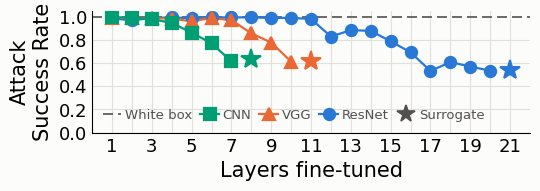

In [4]:
def plot_transfer_vs_layers(df, out, height=2.0, ystep=0.2):
    fig, ax = plt.subplots(figsize=(5.5, height), facecolor=SURFACE)
    style_axes(ax)
    whites, curves = [], {}
    for label in ARCH_ORDER:
        color = ARCH_COLORS[label]
        rows = df[df['label'] == label]
        n_layers = int(rows['n_layers'].iloc[0])
        pts = {int(r.layers_finetuned): r.asr_median for r in rows.itertuples()}
        xs = sorted(pts)
        body = [x for x in xs if x != n_layers]
        # Fine-tuned depths joined by a line; the surrogate star (x = n_layers) stands alone.
        ax.plot(body, [pts[x] for x in body], color=color, ls='-', lw=1.6, zorder=4)
        ax.plot(body, [pts[x] for x in body], ls='none', marker=ARCH_MARKERS[label], ms=8,
                mec=color, mfc=color, mew=1.6, zorder=5)
        if n_layers in pts:
            ax.plot([n_layers], [pts[n_layers]], ls='none', marker=SCRATCH_MARKER,
                    ms=15, mec=color, mfc=color, mew=1.4, zorder=6)
        curves[label] = Line2D([], [], color=color, ls='-', lw=1.6, marker=ARCH_MARKERS[label],
                               ms=8, mec=color, mfc=color, mew=1.6, label=SHORT[label])
        whites.append(rows['white_box_asr'].iloc[0])

    # The white boxes are all ~1.0 at this eps: one grey dashed line at the highest.
    ax.axhline(max(whites), color=INK_2, lw=1.2, ls=(0, (6, 3)), zorder=2)
    wb = Line2D([], [], color=INK_2, lw=1.2, ls=(0, (6, 3)), label='White box')
    star = Line2D([], [], ls='none', marker=SCRATCH_MARKER, ms=13, mec=INK_2,
                  mfc=INK_2, mew=1.2, label='Surrogate')
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    ax.set_ylabel('Attack Success Rate' if height >= 3 else 'Attack\nSuccess Rate',
                  color='black', fontsize=15)
    layers_axis(ax)
    ax.tick_params(axis='y', labelsize=13)
    # One row: White box, CNN, VGG, ResNet, Surrogate.
    handles = [wb] + [curves[n] for n in LEGEND_ORDER] + [star]
    leg = ax.legend(handles=handles, loc='lower left', ncol=len(handles),
                    fontsize=9.5, frameon=False, borderpad=0.3, columnspacing=0.6,
                    handletextpad=0.3, handlelength=1.4, labelspacing=0.25)
    for t in leg.get_texts():
        t.set_color(INK_2)
    # The 1.0 grid line sits on the white-box line and reads as a second line: hide it.
    fig.canvas.draw()
    for tick in ax.yaxis.get_major_ticks():
        if abs(tick.get_loc() - 1.0) < 1e-9:
            tick.gridline.set_visible(False)
    save(fig, out)
    plt.show()


plot_transfer_vs_layers(df, '../plots/fig_transfer_vs_layers_archs_eps5255.pdf')